# Slime Mould Algorithm–Optimised XGBoost for EV Charging Energy Demand
**Bio-Inspired Algorithms (23DS7BSBIO) AAT — B.E. CSE (Data Science), BMSCE Bengaluru**

End-to-end walkthrough for the demo. All logic lives in `src/`; this notebook imports it and
shows the results produced by the pipeline (`python -m src.experiments.*`).

**Problem.** Given information available at the moment an EV plugs in — station and port, plug type,
time and day, and the driver's past charging behaviour — predict the energy (kWh) the session will consume.
XGBoost is the model; the Slime Mould Algorithm (SMA) tunes its hyperparameters and is compared with PSO,
GA, random search and the untuned model.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
from src.config import load_config, results_dir
cfg = load_config()
RES = results_dir(cfg)
pd.set_option("display.precision", 4)
print("Results directory:", RES)

Results directory: E:\EV Charging Station Placement\results


## 1. Dataset and preprocessing
City of Palo Alto *EV Charging Station Usage (July 2011 – Dec 2020)*. We keep 2012–2019, clean the target,
drop **leakage** columns (known only after the session ends, e.g. charging time, fees, GHG savings) and
split **chronologically** 70/15/15.

In [2]:
info = json.loads((ROOT / cfg["paths"]["processed_dir"] / "preprocess_log.json").read_text())
display(pd.DataFrame(info["steps"]))
print(f"Outlier threshold: {info['outlier_threshold_kwh']:.2f} kWh")
display(pd.DataFrame(info["splits"]).T)
print("Dropped columns:", ", ".join(info["dropped_columns"]))

,step,rows
0,raw CSV,259415
1,parse start date,259415
2,filter 2012-2019,238043
3,clean target + outliers,236852
4,drop leakage/identifier columns,236852
5,fill missing values,236852
6,feature engineering,236852


Outlier threshold: 45.97 kWh


,rows,start,end
train,165796,2012-01-01 13:24:00,2018-06-12 18:12:00
val,35528,2018-06-12 18:13:00,2019-04-03 12:05:00
test,35528,2019-04-03 12:14:00,2019-12-31 21:33:00


Dropped columns: MAC Address, Org Name, Start Time Zone, End Date, End Time Zone, Transaction Date (Pacific Time), Total Duration (hh:mm:ss), Charging Time (hh:mm:ss), GHG Savings (kg), Gasoline Savings (gallons), EVSE ID, Address 1, City, State/Province, Country, Currency, Fee, Ended By, Plug In Event Id, County, System S/N, Model Number


In [3]:
from src.data.preprocess import FEATURES, assert_no_leakage, load_splits
train, val, test, meta = load_splits(cfg)
assert_no_leakage(meta["features"], cfg)          # raises if any leakage column slipped in
print(len(FEATURES), "features:", FEATURES)
train[FEATURES + ["energy_kwh"]].head()

19 features: ['hour', 'hour_sin', 'hour_cos', 'dayofweek', 'is_weekend', 'month', 'month_sin', 'month_cos', 'year', 'port_number', 'lat', 'lon', 'driver_zip_known', 'user_prev_sessions', 'user_prev_mean_kwh', 'station_prev_mean_kwh', 'station', 'port_type', 'plug_type']


,hour,hour_sin,hour_cos,dayofweek,is_weekend,month,month_sin,month_cos,year,port_number,lat,lon,driver_zip_known,user_prev_sessions,user_prev_mean_kwh,station_prev_mean_kwh,station,port_type,plug_type,energy_kwh
0,13,-2.5882e-01,-9.6593e-01,6,1,1,0.0,1.0,2012,2,37.4446,-122.1603,1,0,8.0251,8.0251,PALO ALTO CA / HAMILTON #1,Level 2,J1772,7.2152
1,13,-2.5882e-01,-9.6593e-01,6,1,1,0.0,1.0,2012,2,37.4465,-122.1621,1,0,8.0251,8.0251,PALO ALTO CA / BRYANT #2,Level 2,J1772,4.6704
2,18,-1.0000e+00,-1.8370e-16,6,1,1,0.0,1.0,2012,2,37.4446,-122.1603,1,0,8.0251,8.0251,PALO ALTO CA / HAMILTON #2,Level 2,J1772,6.0425
3,18,-1.0000e+00,-1.8370e-16,6,1,1,0.0,1.0,2012,2,37.4446,-122.1603,1,1,7.2152,7.2152,PALO ALTO CA / HAMILTON #1,Level 2,J1772,11.7166
4,12,1.2246e-16,-1.0000e+00,0,0,1,0.0,1.0,2012,2,37.4437,-122.1629,1,0,8.0251,8.0251,PALO ALTO CA / HIGH #4,Level 2,J1772,3.9844


### Exploratory analysis

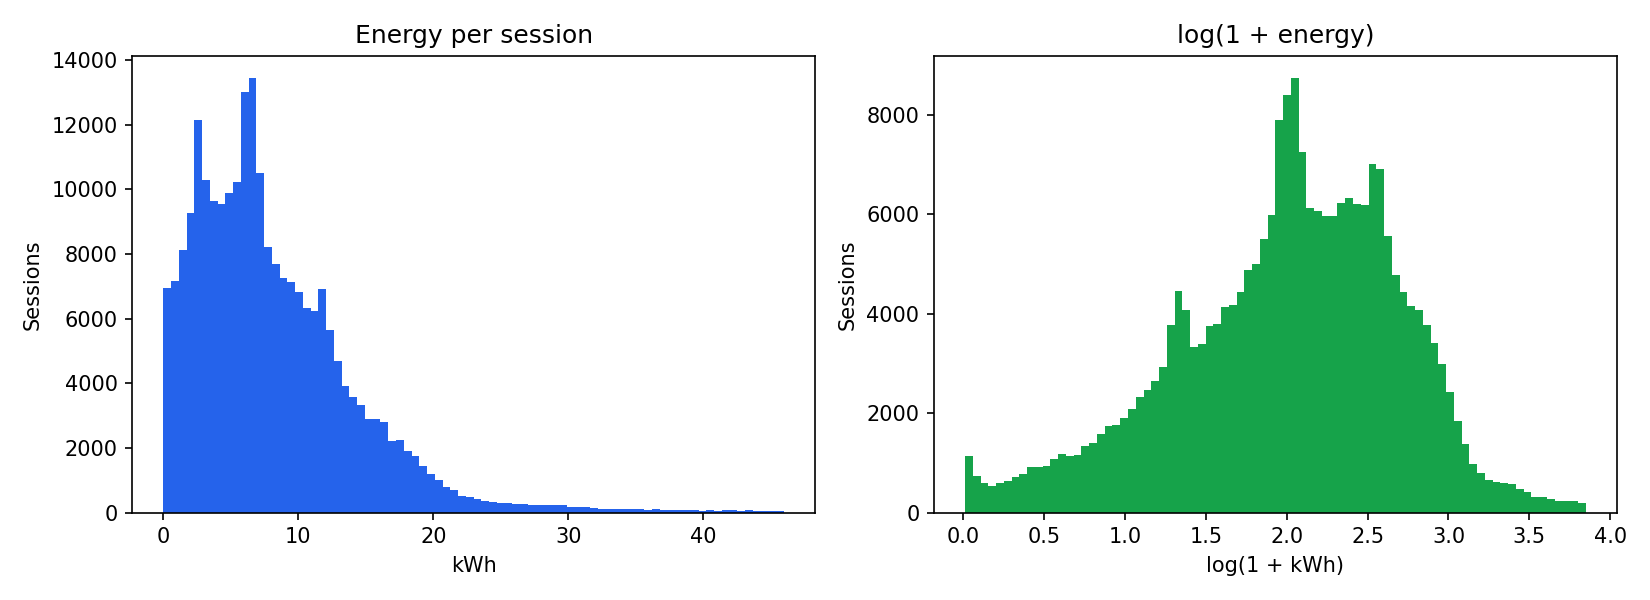

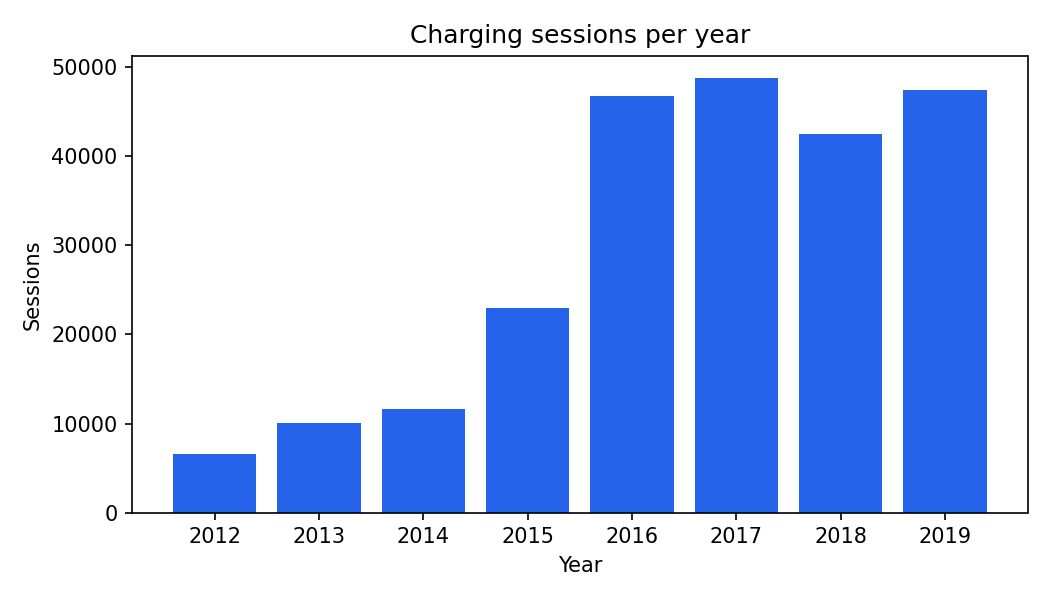

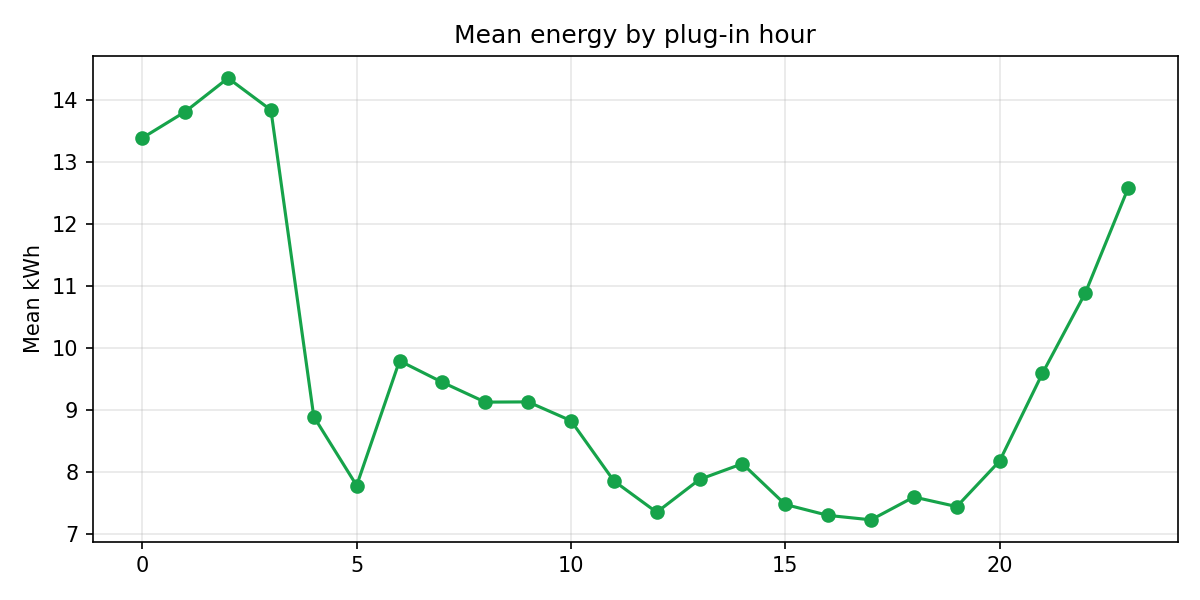

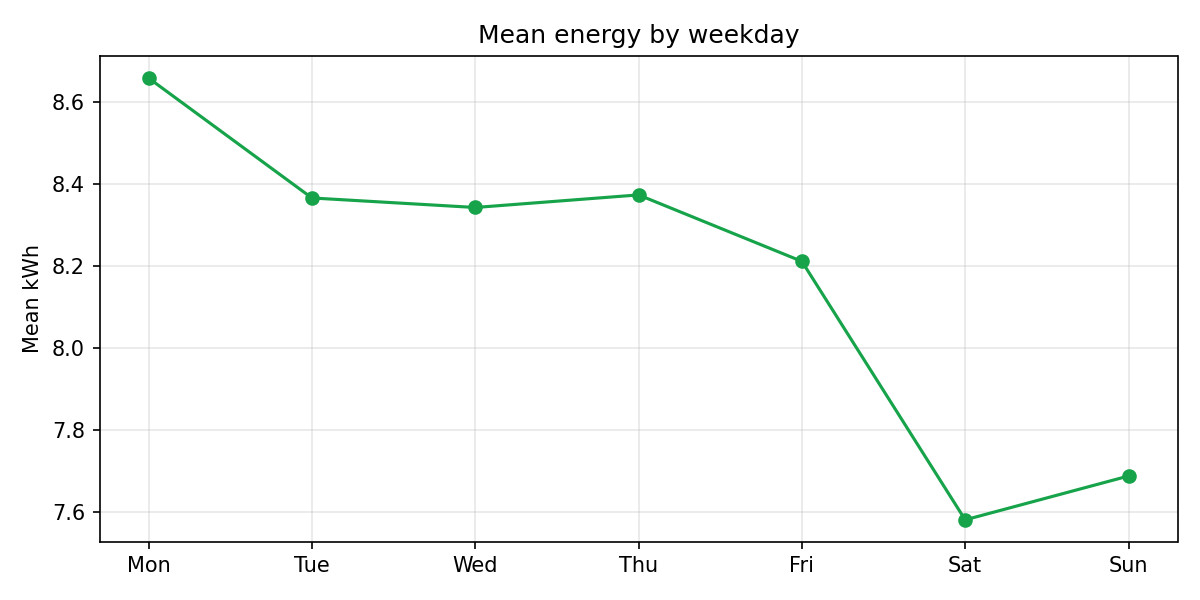

In [4]:
for f in ["target_distribution", "sessions_per_year", "mean_energy_by_hour", "mean_energy_by_weekday"]:
    display(Image(filename=str(RES / "eda" / f"{f}.png"), width=720))

## 2. Baselines (no optimisation)
Linear Regression and Random Forest as references; **default XGBoost** is the baseline the optimisers must beat.

In [5]:
pd.read_csv(RES / "baseline_metrics.csv")

,model,rmse,mae,r2,smape,val_rmse,train_time_s
0,Linear Regression,5.3518,3.5582,0.4073,45.4024,4.9543,1.0350
1,Random Forest,5.4000,3.6245,0.3966,45.7697,4.9384,78.5467
2,XGBoost (default),5.4412,3.6141,0.3873,46.0942,4.9265,2.0713


## 3. The Slime Mould Algorithm
*Physarum polycephalum* reinforces tubes leading to rich food. SMA models this with fitness-ranked
**weights** (vein thickness), an **approach** move toward the best food, a **wrap/contract** move and
random **relocation** (probability z = 0.03). The implementation is `src/optimizers/sma.py` (pure NumPy).

In [6]:
from src.optimizers import SMA, make_optimizer
from src.optimizers.benchmarks import BENCHMARKS
import inspect
print(inspect.getsource(SMA.optimize))

    def optimize(self, fitness_fn: FitnessFn, dim: int) -> OptimizationResult:
        self._start()
        N, T, rng = self.pop_size, self.max_iter, self.rng
        X = rng.uniform(0, 1, (N, dim))
        snapshot_at = max(1, T // 2)              # iteration whose weights are kept for the viva figure
        extras: dict = {}

        for t in range(1, T + 1):
            S = self._evaluate(fitness_fn, X)     # clips X, updates DF / Xb
            DF, Xb = self._best_f, self._best_x
            order = np.argsort(S, kind="stable")
            W = self.compute_weights(S, order, dim)
            if t == snapshot_at:
                extras["weights_snapshot"] = {"iteration": t, "fitness": S.tolist(),
                                              "rank": np.argsort(order).tolist(), "weights": W.tolist()}
            self._record(t, S)

            a = np.arctanh(1 - t / T)             # t >= 1, so the argument is < 1; a -> 0 as t -> T
            b = 1 - t / T

            for i in rang

### Sanity check on benchmark functions (D = 10, 10 seeds)

In [7]:
res = SMA(pop_size=20, max_iter=200, seed=1).optimize(BENCHMARKS["sphere"], dim=5)
print(f"SMA on Sphere (D=5): best fitness = {res.best_fitness:.2e} after {res.evaluations} evaluations")
bench = RES / "benchmarks" / "benchmark_stats.csv"
display(pd.read_csv(bench)) if bench.exists() else print("run: python -m src.experiments.run_benchmarks")

SMA on Sphere (D=5): best fitness = 3.88e-04 after 4000 evaluations


,function,optimizer,mean,std,best,worst
0,Sphere,SMA,1.5380e-02,7.9536e-03,0.0042,2.7569e-02
1,Sphere,PSO,1.9230e-03,2.7727e-03,0.0001,8.7224e-03
2,Sphere,GA,8.5557e-02,8.7110e-02,0.0038,2.1921e-01
3,Sphere,Random,5.5131e+03,1.5857e+03,1781.3187,8.0690e+03
4,Rastrigin,SMA,1.1998e+01,5.6086e+00,6.0197,2.0933e+01
5,Rastrigin,PSO,7.8611e+00,2.4255e+00,5.1436,1.2096e+01
6,Rastrigin,GA,4.6775e-01,6.9429e-01,0.0143,2.0491e+00
7,Rastrigin,Random,7.5369e+01,6.6868e+00,65.0787,8.7055e+01
8,Ackley,SMA,2.5224e-01,1.2469e-01,0.0911,4.4009e-01
9,Ackley,PSO,1.0821e-02,3.2715e-03,0.0048,1.5049e-02


### Vein thickness: the weight W of every cell
The better half of the population gets W > 1, the worse half W < 1.

In [8]:
sma = SMA(6, 1, seed=0)
S = np.array([5.2, 4.9, 5.0, 5.6, 5.1, 5.3])        # e.g. validation RMSEs of 6 cells
order = np.argsort(S)
W = sma.compute_weights(S, order, dim=3)
pd.DataFrame(W, columns=["W_d1", "W_d2", "W_d3"]).assign(fitness=S, rank=np.argsort(order)).sort_values("rank")

,W_d1,W_d2,W_d3,fitness,rank
1,1.0000,1.0000,1.0000,4.9,0
2,1.0010,1.0472,1.0529,5.0,1
4,1.0662,1.0796,1.0593,5.1,2
0,0.8552,0.8736,0.9996,5.2,3
5,0.8317,0.9934,0.8568,5.3,4
3,0.9471,0.7402,0.8370,5.6,5


## 4. The XGBoost search space (9-D)
Every optimiser searches u ∈ [0,1]^9; `SearchSpace.decode` maps it to hyperparameters
(learning rate and the L1/L2 penalties are log-uniform).

In [9]:
from src.models.xgb_space import SearchSpace
space = SearchSpace()
pd.DataFrame({"u = 0": space.decode(np.zeros(9)), "u = 0.5": space.decode(np.full(9, .5)), "u = 1": space.decode(np.ones(9))})

,u = 0,u = 0.5,u = 1
n_estimators,100.000,550.0000,1000.0
max_depth,3.000,8.0000,12.0
learning_rate,0.010,0.0548,0.3
subsample,0.500,0.7500,1.0
colsample_bytree,0.500,0.7500,1.0
min_child_weight,1.000,5.5000,10.0
gamma,0.000,2.5000,5.0
reg_lambda,0.001,0.1000,10.0
reg_alpha,0.001,0.1000,10.0


### A tiny live tuning run
Fitness = validation RMSE of XGBoost trained on a training subsample. (The real experiment uses
pop 15 × 20 iterations × 5 seeds with a 40k-row subsample; here 4 × 3 on 5k rows so it runs in seconds.)

In [10]:
from src.experiments.common import Data
from src.models.xgb_space import XGBFitness
d = Data(train, val, test, meta)
fit = XGBFitness(d.X("train"), d.y("train"), d.X("val"), d.y("val"), seed=1, sample_size=5000, early_stopping_rounds=20)
demo = SMA(pop_size=4, max_iter=3, seed=1).optimize(fit, space.dim)
print("convergence (val RMSE):", [round(c, 4) for c in demo.convergence])
print("best hyperparameters:", space.decode(demo.best_position))

convergence (val RMSE): [5.0116, 5.0116, 5.0103]
best hyperparameters: {'n_estimators': 174, 'max_depth': 5, 'learning_rate': 0.04097, 'subsample': 0.7316, 'colsample_bytree': 0.9423, 'min_child_weight': 3.85, 'gamma': 0.1073, 'reg_lambda': 2.018, 'reg_alpha': 0.001768}


## 5. Results of the full experiment

In [11]:
summary_md = RES / "summary.md"
if summary_md.exists() and "quick" in summary_md.read_text()[:300]:
    display(Markdown("> **Note:** results below are from the quick smoke test."))
comp = pd.read_csv(RES / "final_comparison.csv")
comp[["model", "rmse", "mae", "r2", "smape", "rmse_improvement_pct", "train_time_s"]]

,model,rmse,mae,r2,smape,rmse_improvement_pct,train_time_s
0,Linear Regression,5.3518,3.5582,0.4073,45.4024,1.6436,1.0350
1,Random Forest,5.4000,3.6245,0.3966,45.7697,0.7570,78.5467
2,XGBoost (default),5.4412,3.6141,0.3873,46.0942,0.0000,2.0713
3,XGBoost + Random,5.3054,3.5053,0.4175,45.1447,2.4954,11.6053
4,XGBoost + GA,5.3113,3.5158,0.4162,45.3667,2.3876,9.4761
5,XGBoost + PSO,5.3067,3.5064,0.4173,45.1656,2.4730,20.3205
6,XGBoost + SMA,5.3016,3.5047,0.4184,45.0786,2.5657,16.8283


In [12]:
display(pd.read_csv(RES / "tuning_summary.csv")[["optimizer", "n_runs", "val_rmse_mean", "test_rmse_mean", "test_rmse_std", "runtime_s_mean"]])
display(pd.read_csv(RES / "wilcoxon.csv"))

,optimizer,n_runs,val_rmse_mean,test_rmse_mean,test_rmse_std,runtime_s_mean
0,GA,5,4.8839,5.3100,0.0031,816.7377
1,PSO,5,4.8846,5.3101,0.0049,1359.0314
2,Random,5,4.8854,5.3125,0.0068,901.7004
3,SMA,5,4.8879,5.3052,0.0038,961.8588


,comparison,metric,n_pairs,sma_mean,other_mean,sma_wins,statistic,p_value,note
0,SMA vs PSO,test_rmse,5,5.3052,5.3101,4,1.0,0.1250,low power (few seeds)
1,SMA vs GA,test_rmse,5,5.3052,5.3100,4,1.0,0.1250,low power (few seeds)
2,SMA vs Random,test_rmse,5,5.3052,5.3125,5,0.0,0.0625,low power (few seeds)


**convergence_mean**

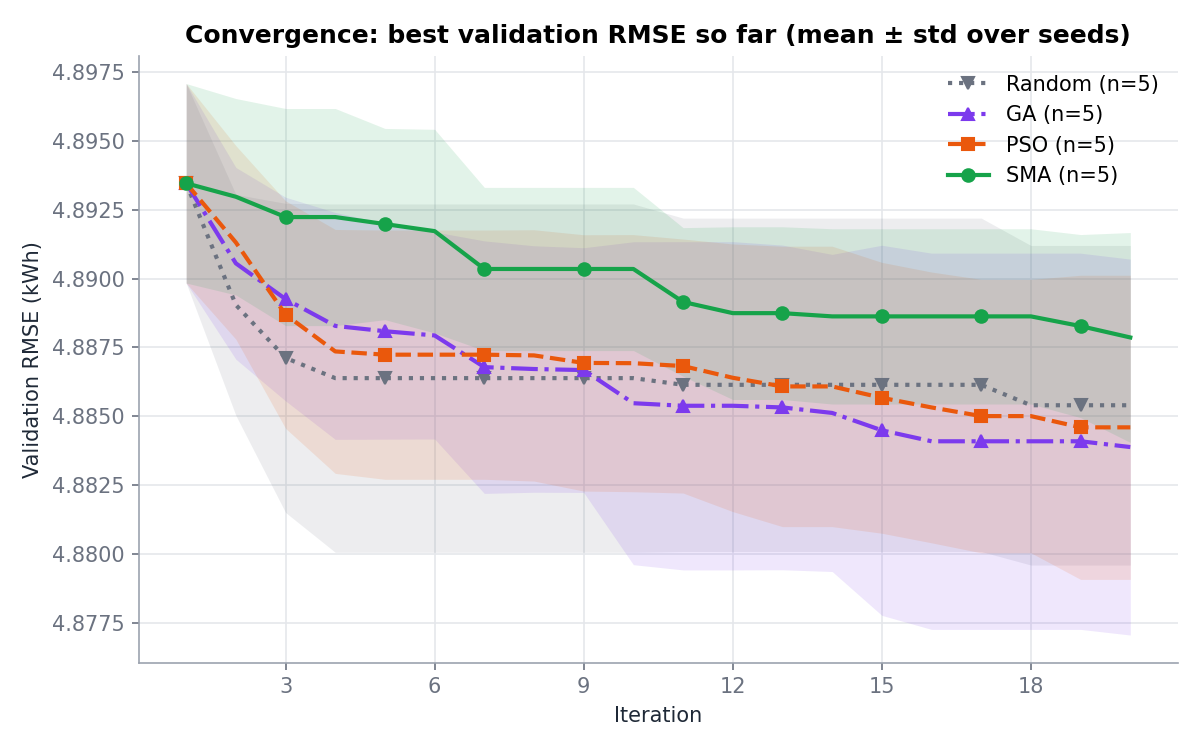

**convergence_sma_runs**

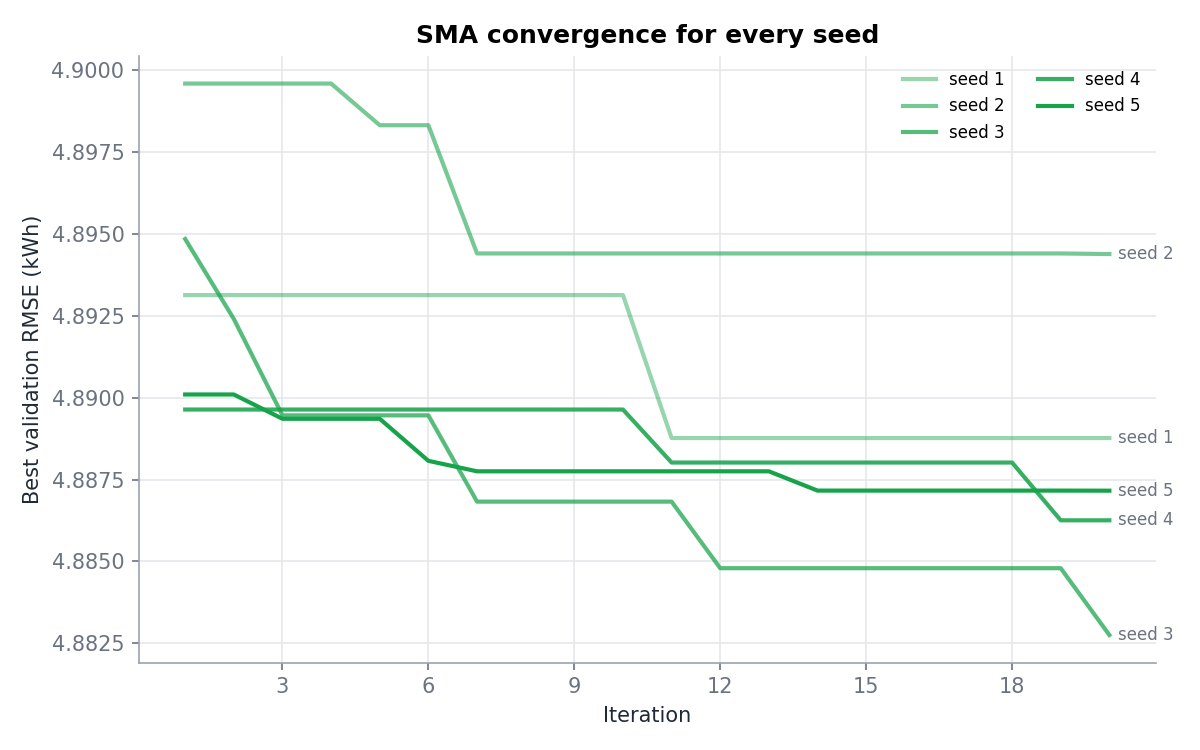

**learning_curve_default_vs_sma**

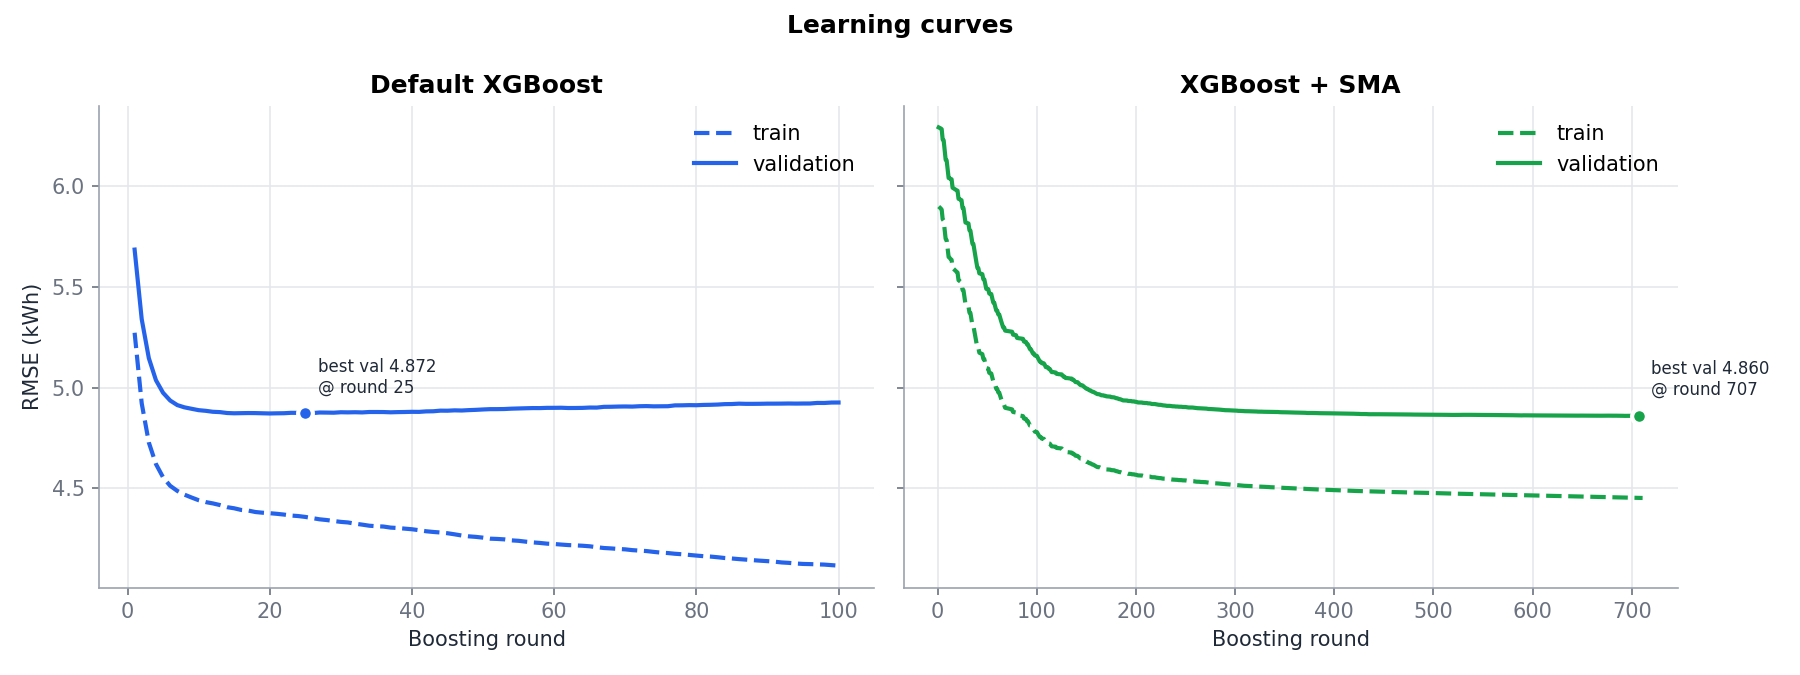

**baseline_vs_optimized_bar**

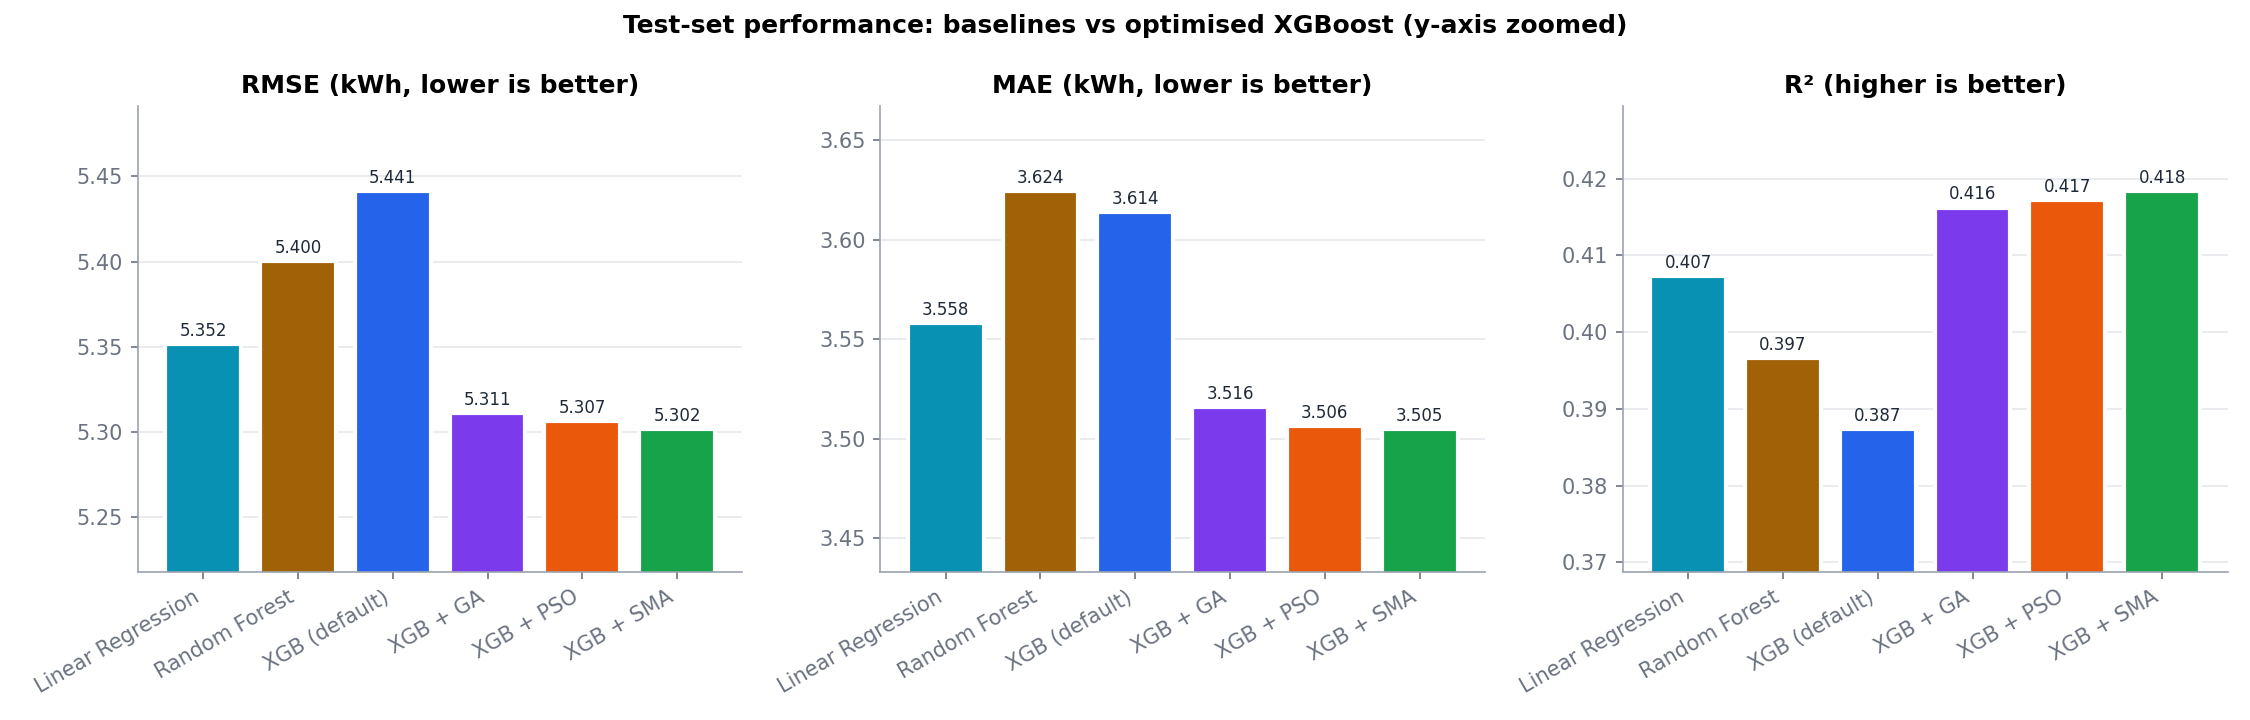

**boxplot_test_rmse**

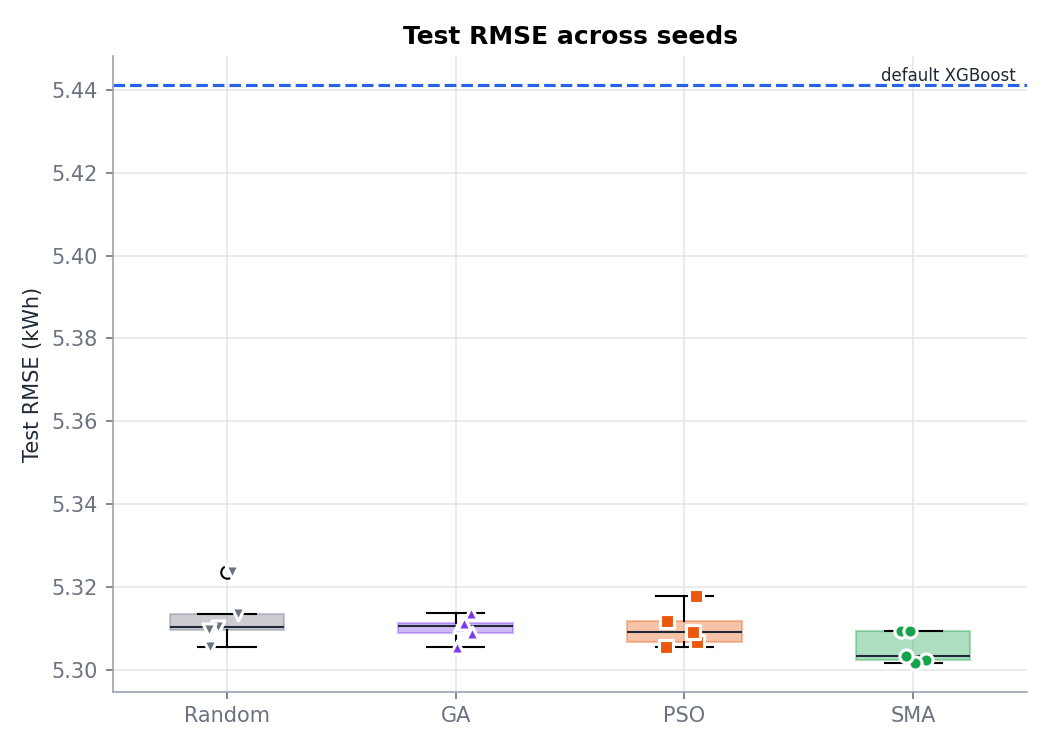

**pred_vs_actual_sma**

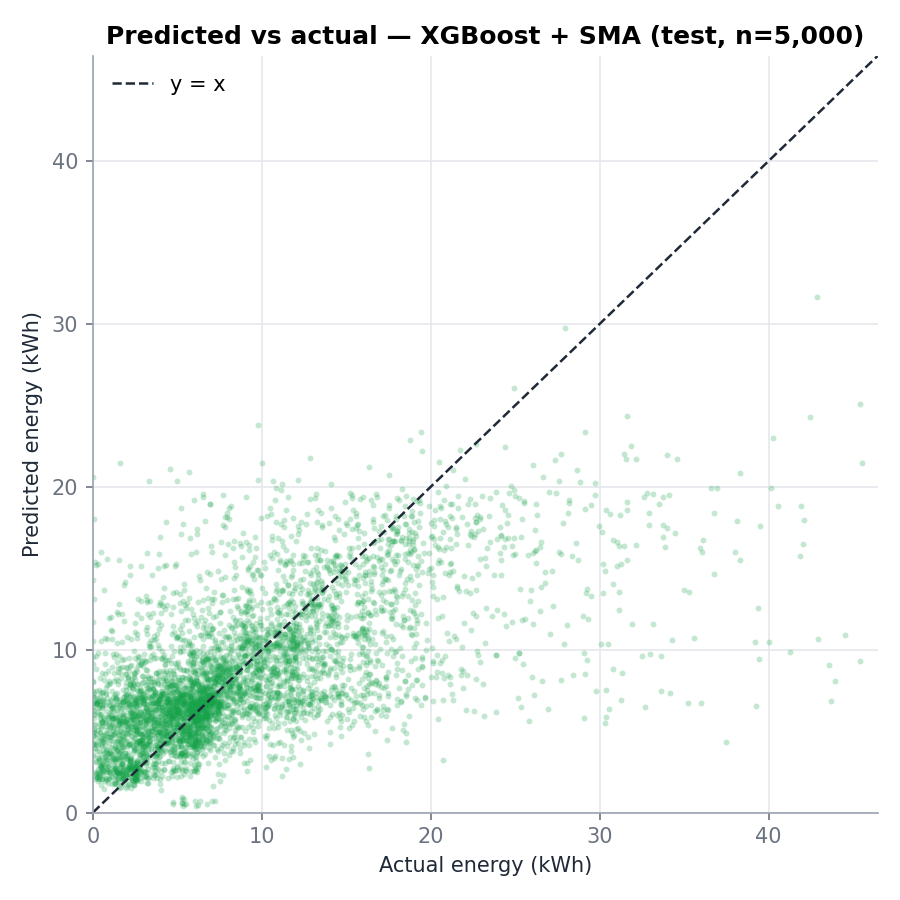

**residuals_sma**

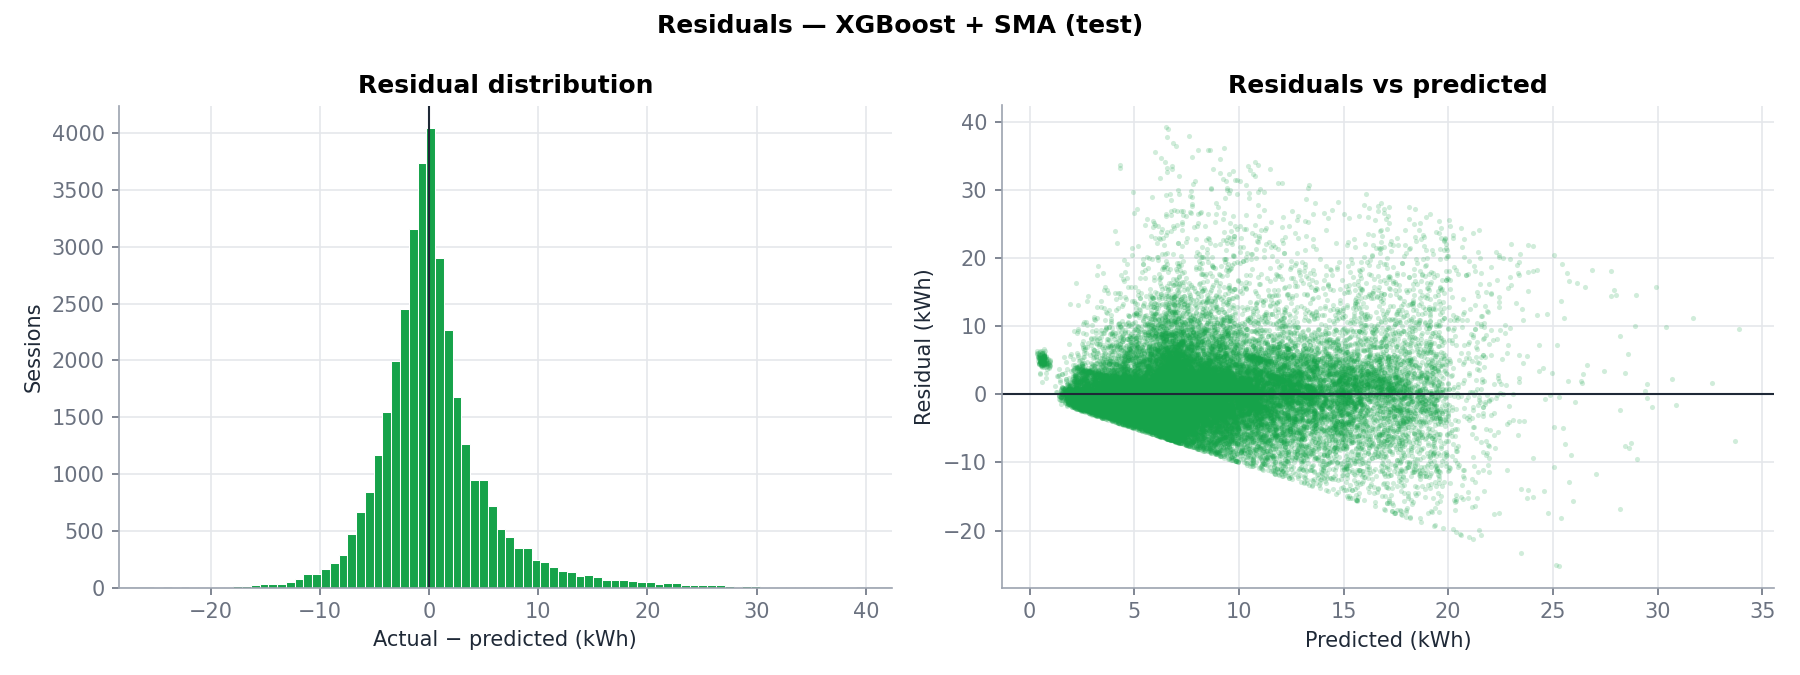

**feature_importance_sma**

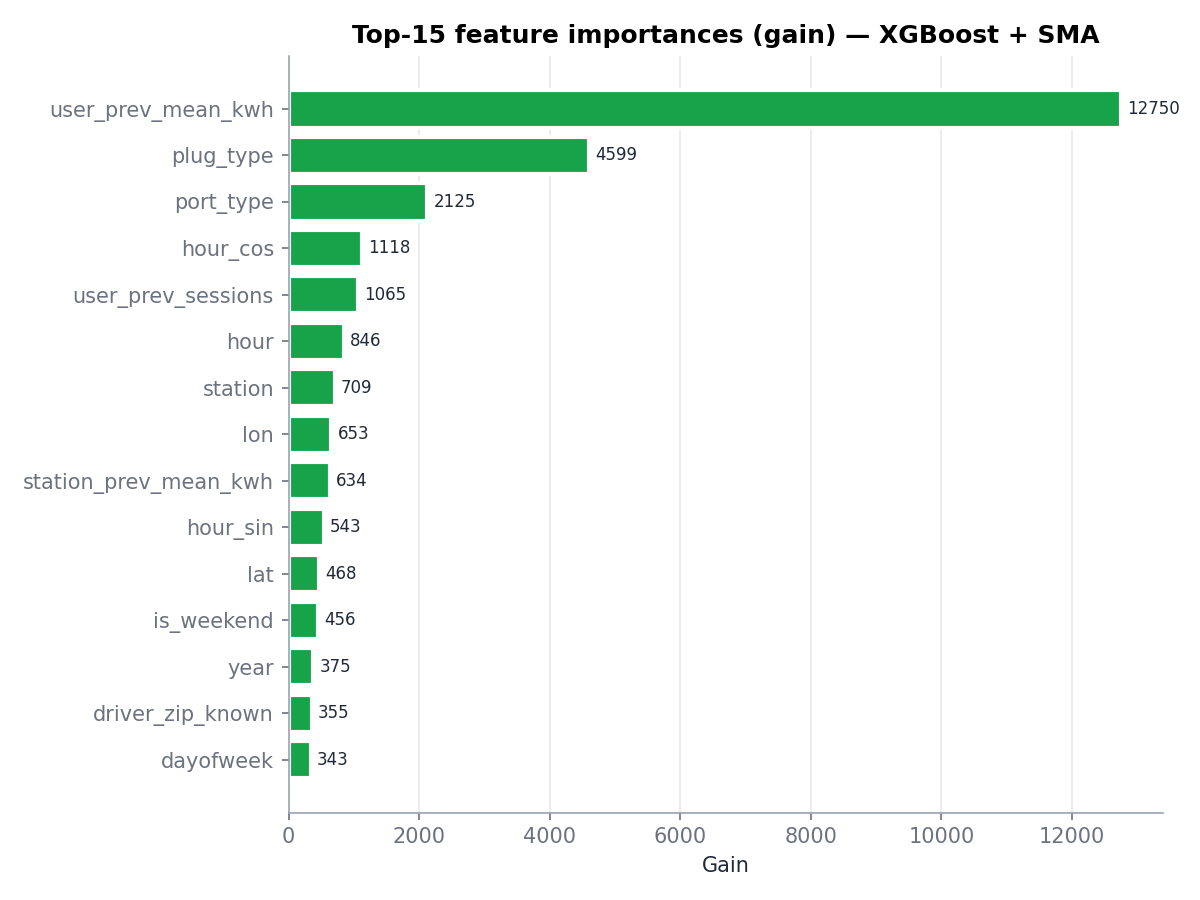

**hyperparams_comparison**

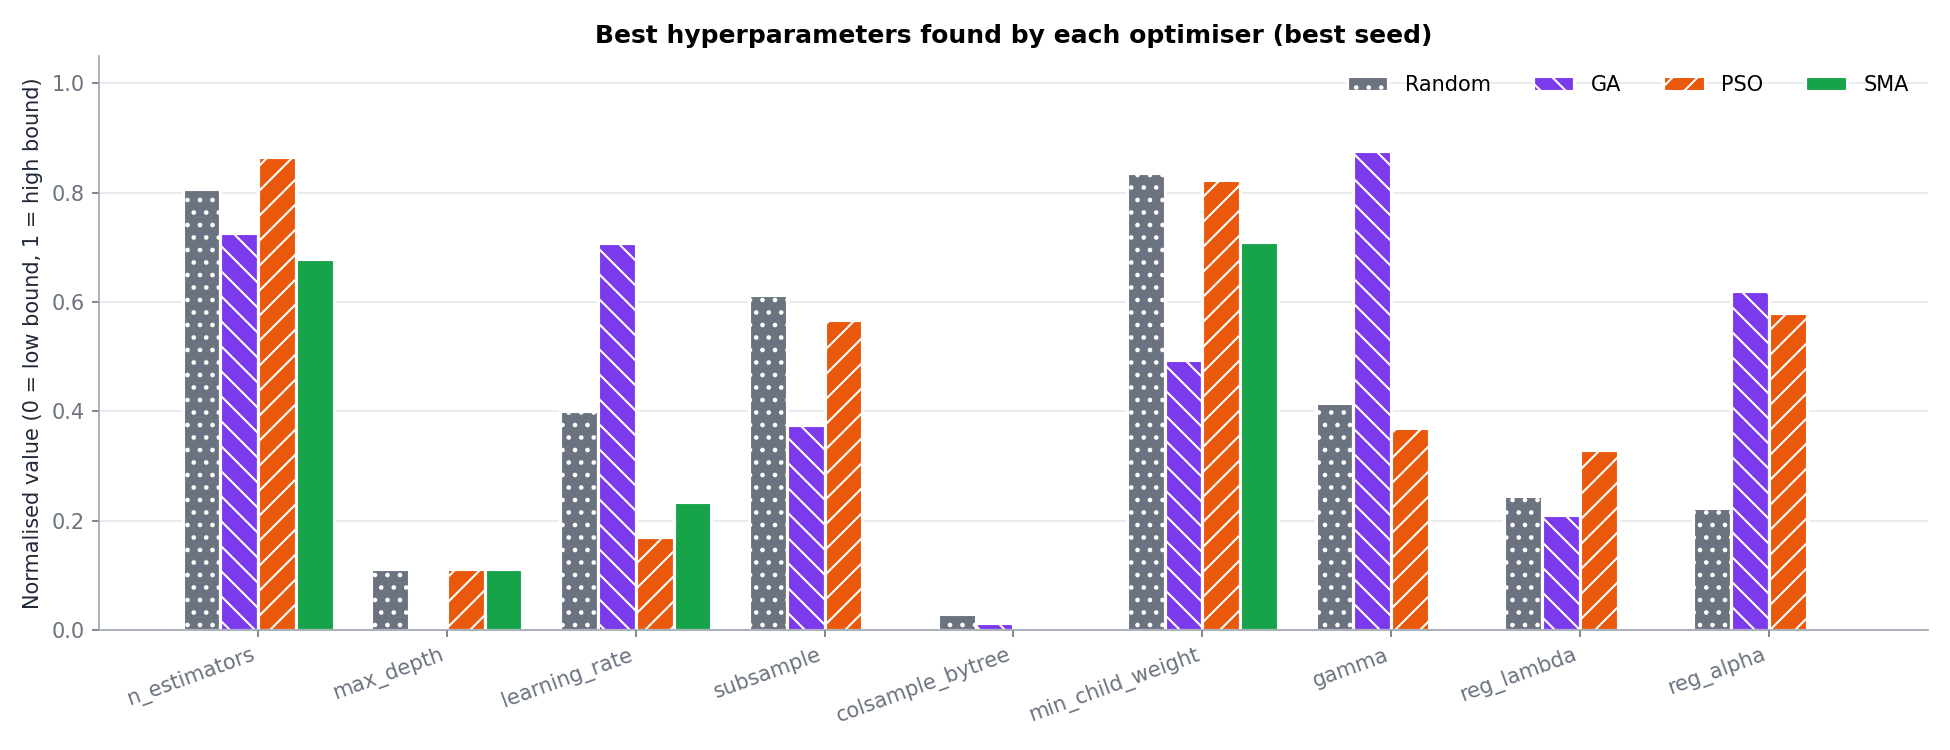

**runtime_vs_rmse**

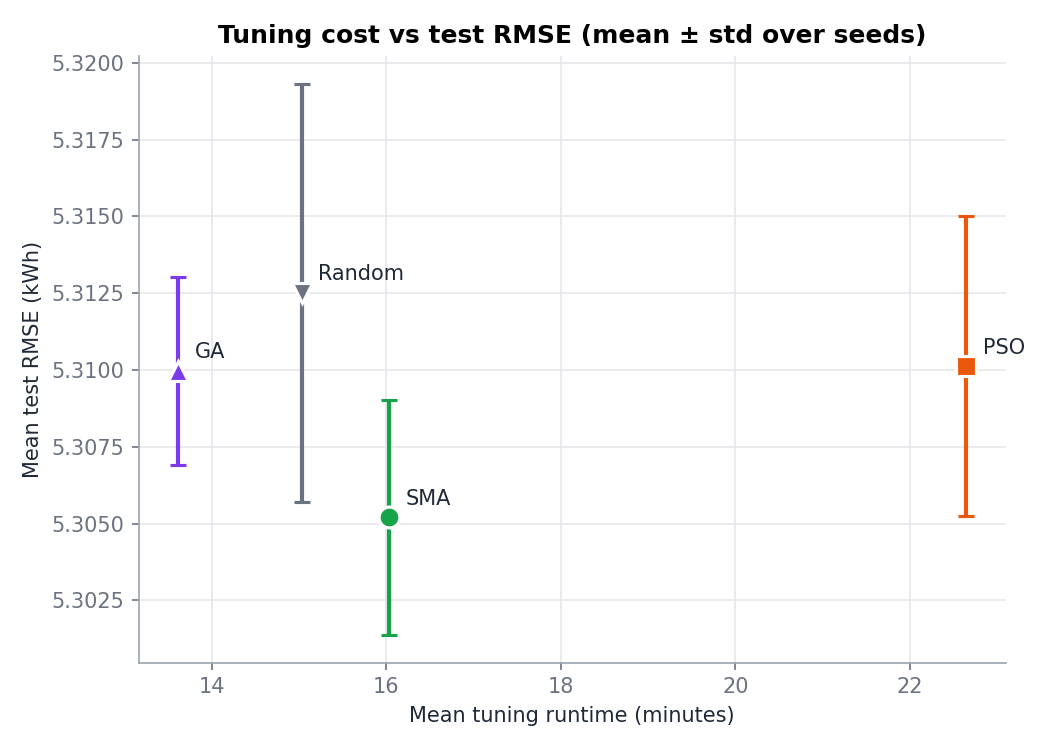

**sma_weights_explained**

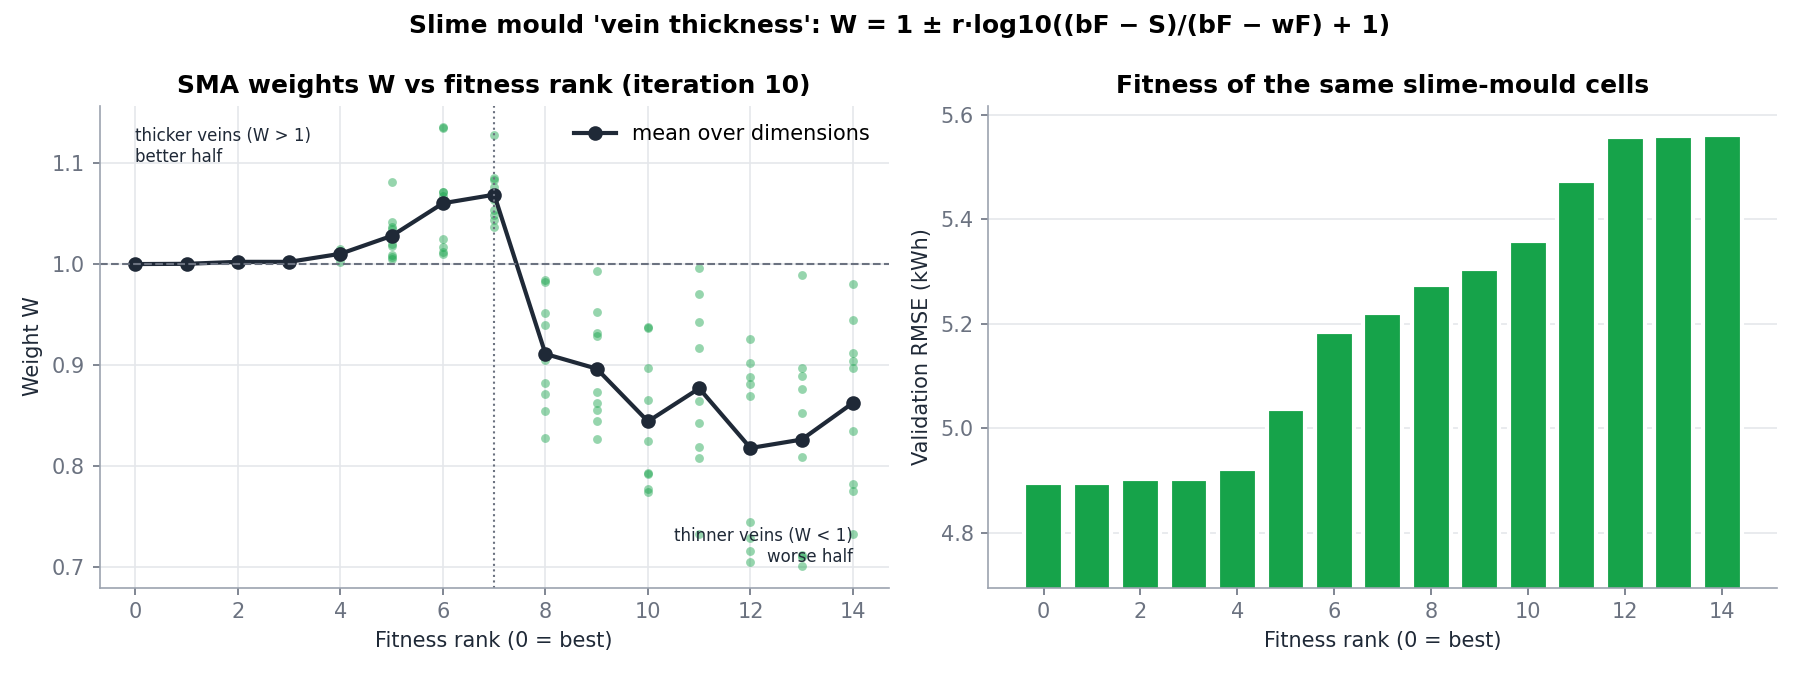

In [13]:
for f in ["convergence_mean", "convergence_sma_runs", "learning_curve_default_vs_sma", "baseline_vs_optimized_bar",
          "boxplot_test_rmse", "pred_vs_actual_sma", "residuals_sma", "feature_importance_sma",
          "hyperparams_comparison", "runtime_vs_rmse", "sma_weights_explained"]:
    p = RES / "figures" / f"{f}.png"
    if p.exists():
        display(Markdown(f"**{f}**")); display(Image(filename=str(p), width=820))

## 6. Known limitations
* Palo Alto data — patterns may differ from Indian cities; the method transfers, the numbers may not.
* Per-session energy is very noisy (driver behaviour), so R² is moderate; the focus is the improvement from tuning.
* Tuning uses a training subsample for speed; tuned hyperparameters are re-fitted on the full training set.
* Only 5 seeds per optimiser; the Wilcoxon test has limited power.
* In the normalised [0,1] space SMA's wrap move contracts toward the lower bounds — a property of the original algorithm.